# Homework 8.1 - Task 2

## Exact Score of the Two-Component Gaussian Mixture

The score is

$$
s(x,t)
=
\frac{\partial}{\partial x}
\log p_t(x).
$$

For the symmetric mixture, the score can be expressed through the posterior responsibilities of the two components.

## 1. Responsibilities

Let

$$
m(t)=2\alpha(t)
$$

and

$$
v(t)=\sigma(t)^2.
$$

Let $r_+(x,t)$ be the responsibility of the component with mean $m(t)$.

Then

$$
r_+(x,t)
=
\frac{N(x;m(t),v(t))}
{N(x;m(t),v(t))+N(x;-m(t),v(t))}.
$$

The other responsibility is

$$
r_-(x,t)=1-r_+(x,t).
$$

For the symmetric case,

$$
2r_+(x,t)-1
=
\tanh\left(
\frac{m(t)x}{v(t)}
\right).
$$

## 2. Score formula

Each Gaussian component has score

$$
\frac{\mu-x}{v}.
$$

Therefore the mixture score is the responsibility-weighted average

$$
s(x,t)
=
r_+(x,t)
\frac{m(t)-x}{v(t)}
+
r_-(x,t)
\frac{-m(t)-x}{v(t)}.
$$

Equivalently,

$$
s(x,t)
=
\frac{
m(t)
\tanh\left(
\frac{m(t)x}{v(t)}
\right)
-x
}{
v(t)
}.
$$

At the final time,

$$
m(1)=0
$$

and

$$
v(1)=1,
$$

so

$$
s(x,1)=-x.
$$

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_1"

config = json.loads(
    (
        DATA_DIR
        / "task1_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

A = float(config["a"])
SIGMA0 = float(config["sigma0"])
Q = float(config["q"])

In [2]:
def alpha(t):
    return np.cos(
        0.5
        * np.pi
        * np.asarray(
            t,
            dtype=float,
        )
    )


def variance(t):
    a = alpha(t)
    return (
        1.0
        - Q * a**2
    )


def normal_density(
    x,
    mean,
    var,
):
    x = np.asarray(
        x,
        dtype=float,
    )

    return (
        np.exp(
            -0.5
            * (x - mean)**2
            / var
        )
        / np.sqrt(
            2.0
            * np.pi
            * var
        )
    )


def mixture_density(
    x,
    t,
):
    m = A * alpha(t)
    v = variance(t)

    return (
        0.5
        * normal_density(
            x,
            -m,
            v,
        )
        + 0.5
        * normal_density(
            x,
            m,
            v,
        )
    )


def responsibility_plus(
    x,
    t,
):
    x = np.asarray(
        x,
        dtype=float,
    )

    m = A * alpha(t)
    v = variance(t)

    return (
        0.5
        * (
            1.0
            + np.tanh(
                m * x / v
            )
        )
    )


def exact_score(
    x,
    t,
):
    x = np.asarray(
        x,
        dtype=float,
    )

    m = A * alpha(t)
    v = variance(t)

    return (
        m
        * np.tanh(
            m * x / v
        )
        - x
    ) / v

## 3. Validate the responsibilities

The two responsibilities must sum to one.

They must also agree with the direct Gaussian-density ratio.

In [3]:
x_check = np.linspace(
    -5.0,
    5.0,
    10001,
)

times = [
    0.0,
    0.25,
    0.50,
    0.75,
    0.95,
    1.0,
]

responsibility_rows = []

for t in times:
    m = A * alpha(t)
    v = variance(t)

    plus_direct = (
        normal_density(
            x_check,
            m,
            v,
        )
        /
        (
            normal_density(
                x_check,
                m,
                v,
            )
            +
            normal_density(
                x_check,
                -m,
                v,
            )
        )
    )

    plus_closed = (
        responsibility_plus(
            x_check,
            t,
        )
    )

    responsibility_rows.append({
        "t": t,
        "max_abs_difference_direct_vs_closed": float(
            np.max(
                np.abs(
                    plus_direct
                    - plus_closed
                )
            )
        ),
        "max_abs_sum_to_one_error": float(
            np.max(
                np.abs(
                    plus_closed
                    + (1.0 - plus_closed)
                    - 1.0
                )
            )
        ),
    })


responsibility_validation = pd.DataFrame(
    responsibility_rows
)

responsibility_validation.to_csv(
    DATA_DIR
    / "task2_responsibility_validation.csv",
    index=False,
)

print(
    responsibility_validation.to_string(
        index=False
    )
)

   t  max_abs_difference_direct_vs_closed  max_abs_sum_to_one_error
0.00                         8.881784e-16                       0.0
0.25                         4.996004e-16                       0.0
0.50                         2.220446e-16                       0.0
0.75                         2.220446e-16                       0.0
0.95                         9.992007e-16                       0.0
1.00                         3.330669e-16                       0.0


## 4. Validate the analytic score against a numerical derivative

We compare the analytic score with a centered finite-difference derivative of $\log p_t(x)$.

Boundary grid points are excluded from the maximum-error summary.

In [4]:
score_rows = []

x_grid = np.linspace(
    -5.0,
    5.0,
    20001,
)

dx = x_grid[1] - x_grid[0]

for t in times:
    density = mixture_density(
        x_grid,
        t,
    )

    log_density = np.log(
        np.maximum(
            density,
            1e-300,
        )
    )

    numerical_score = np.gradient(
        log_density,
        dx,
        edge_order=2,
    )

    analytic_score = exact_score(
        x_grid,
        t,
    )

    interior = slice(
        10,
        -10,
    )

    error = (
        numerical_score[
            interior
        ]
        - analytic_score[
            interior
        ]
    )

    score_rows.append({
        "t": t,
        "rmse": float(
            np.sqrt(
                np.mean(
                    error**2
                )
            )
        ),
        "max_abs_error": float(
            np.max(
                np.abs(
                    error
                )
            )
        ),
    })


score_validation = pd.DataFrame(
    score_rows
)

score_validation_path = (
    DATA_DIR
    / "task2_score_finite_difference_validation.csv"
)

score_validation.to_csv(
    score_validation_path,
    index=False,
)

print(
    score_validation.to_string(
        index=False
    )
)

   t         rmse  max_abs_error
0.00 7.886214e-05   1.050967e-03
0.25 3.541335e-06   2.537188e-05
0.50 1.574160e-07   6.050819e-07
0.75 1.009339e-08   2.239736e-08
0.95 9.930082e-11   1.367040e-10
1.00 2.381993e-12   1.023182e-11


## 5. Plot the score at several times

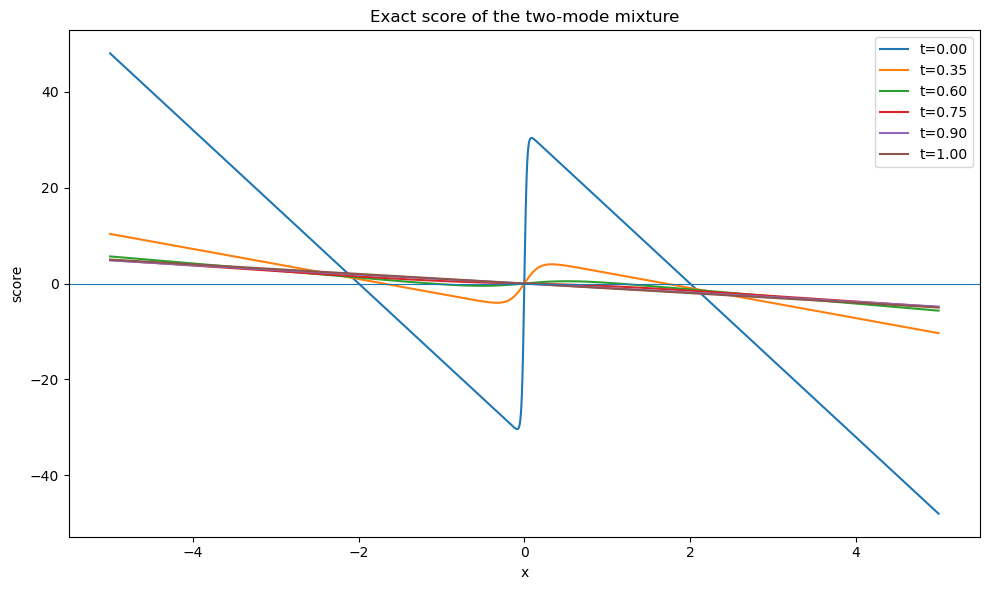

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task2_exact_score_curves.png


In [5]:
plot_times = [
    0.0,
    0.35,
    0.60,
    0.75,
    0.90,
    1.0,
]

x_plot = np.linspace(
    -5.0,
    5.0,
    3000,
)

plt.figure(
    figsize=(10, 6)
)

for t in plot_times:
    plt.plot(
        x_plot,
        exact_score(
            x_plot,
            t,
        ),
        label=f"t={t:.2f}",
    )

plt.axhline(
    0.0,
    linewidth=0.8,
)

plt.xlabel("x")
plt.ylabel("score")
plt.title(
    "Exact score of the two-mode mixture"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task2_exact_score_curves.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 2 Conclusion

The exact responsibility formula and the exact score agree numerically with their direct definitions.

At the final time, the score becomes the standard Gaussian score

$$
s(x,1)=-x.
$$

Task 3 studies how the score directions and the visible density modes change while the components merge.